# Task 1: Data Cleaning, Geospatial Wrangling, and Exploration

### 1. Importing and merging of the administrative boundary files for TOgo and Bening - Plot of the administrative polygons

In [74]:
import geopandas as gpd
import pandas as pd
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np 
import rioxarray 
import xarray as xr 
from rasterio.features import geometry_mask
from rasterstats import zonal_stats 
import warnings
import random
from scipy import stats
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline 
from sklearn.metrics import r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler


In [75]:
# Load the administrative boundary files

togo_gdf = gpd.read_file(r"instructions and data\data\administrative_boundaries\gadm41_TGO_2.geojson")
benin_gdf = gpd.read_file(r"instructions and data\data\administrative_boundaries\gadm41_BEN_2.geojson")

# Check and align Coordinate Reference Systems (CRS)
if togo_gdf.crs != benin_gdf.crs:
  benin_gdf = benin_gdf.to_crs(togo_gdf.crs)

# Add a column to keep track of the country if it doesn't already exist
togo_gdf["country_name"] = "Togo"
benin_gdf["country_name"] = "Benin"

# Merge (concatenate) the two GeoDataFrames
merged_gdf = gpd.GeoDataFrame(
    pd.concat([togo_gdf, benin_gdf], ignore_index=True), crs=togo_gdf.crs
)

# Inspect the merged data
print(merged_gdf[["country_name", "geometry"]].head(100))
print(f"Total administrative units merged: {len(merged_gdf)}")

# Export the merged boundaries 
merged_gdf.to_file("togo_benin_merged.geojson", driver="GeoJSON")


   country_name                                           geometry
0          Togo  MULTIPOLYGON (((0.6222 7.9015, 0.6227 7.9017, ...
1          Togo  MULTIPOLYGON (((0.6173 8.5135, 0.6118 8.5127, ...
2          Togo  MULTIPOLYGON (((0.9443 8.3788, 0.9321 8.3845, ...
3          Togo  MULTIPOLYGON (((1.2352 8.396, 1.2354 8.414, 1....
4          Togo  MULTIPOLYGON (((1.2391 8.6754, 1.2335 8.6737, ...
..          ...                                                ...
95        Benin  MULTIPOLYGON (((2.6924 6.449, 2.6784 6.4455, 2...
96        Benin  MULTIPOLYGON (((2.566 6.6439, 2.5563 6.6239, 2...
97        Benin  MULTIPOLYGON (((2.4813 6.4445, 2.494 6.4655, 2...
98        Benin  MULTIPOLYGON (((2.5815 6.5086, 2.5708 6.503, 2...
99        Benin  MULTIPOLYGON (((2.6968 6.5581, 2.7051 6.5454, ...

[100 rows x 2 columns]
Total administrative units merged: 118


In [76]:
# Auto-detect the Admin Level 1 column name (e.g., 'NAME_1' in GADM, 'ADM1_FR' or 'ADM1_EN' in HDX)
possible_adm1_cols = ["NAME_1", "ADM1_FR", "ADM1_EN", "region", "departement"]
adm1_col = next(
    (col for col in possible_adm1_cols if col in merged_gdf.columns), None
)

if adm1_col is None:
  print("Available columns in your dataset:", merged_gdf.columns.tolist())
  raise KeyError(
      "No standard Admin Level 1 column found. Please set 'adm1_col' manually."
  )

print(f"Detected Admin Level 1 column: '{adm1_col}'")

# Dissolve Level 2 polygons by country and Level 1 name to reconstruct Level 1 boundaries
gdf_level1 = merged_gdf.dissolve(
    by=["country_name", adm1_col], as_index=False
)

Detected Admin Level 1 column: 'NAME_1'


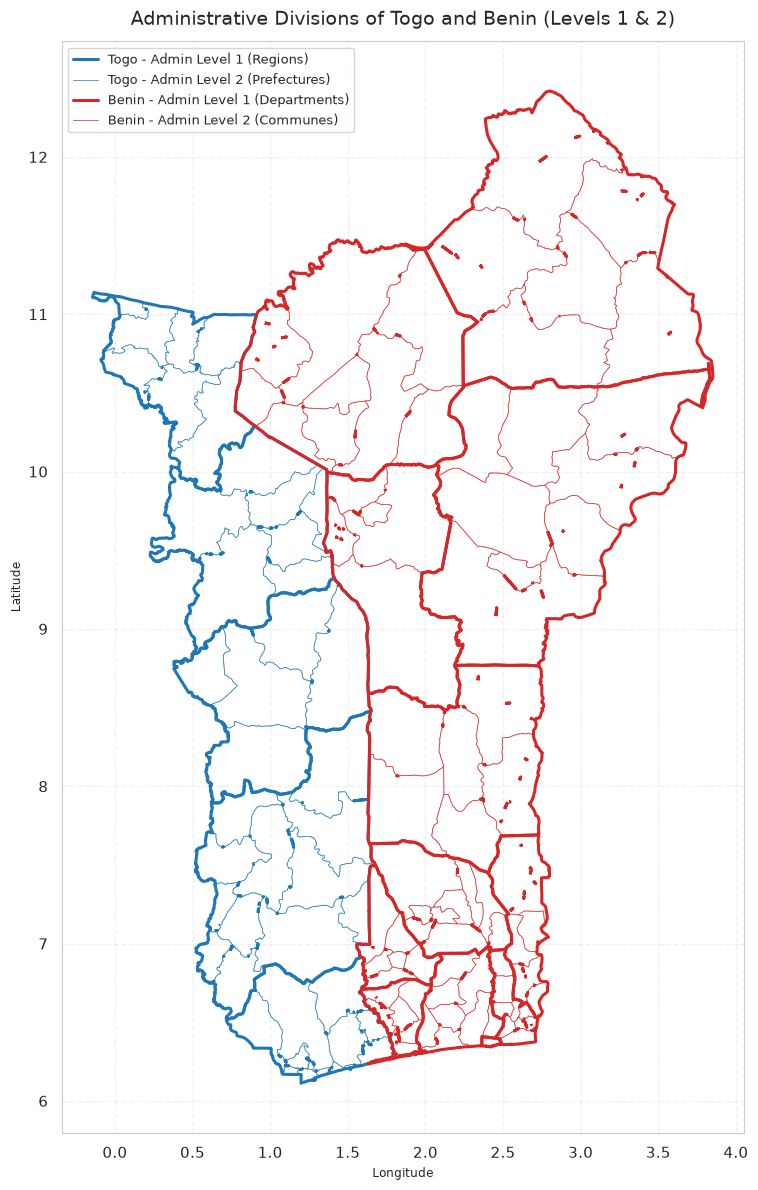

In [77]:
# Plot the administrative boundaries
fig, ax = plt.subplots(figsize=(10, 12))
country_colors = {"Togo": "#1f77b4", "Benin": "#d62728"}  # Blue for Togo, Red for Benin

for country, color in country_colors.items():
  # Plot Level 2 boundaries (thinner lines: prefectures / communes)
  subset_adm2 = merged_gdf[merged_gdf["country_name"] == country]
  subset_adm2.boundary.plot(ax=ax, color=color, linewidth=0.5, alpha=0.75)

  # Plot Level 1 boundaries on top (thicker lines: regions / departments)
  subset_adm1 = gdf_level1[gdf_level1["country_name"] == country]
  subset_adm1.boundary.plot(ax=ax, color=color, linewidth=2.2)

# Legend 
legend_handles = [
    mlines.Line2D([], [], color=country_colors["Togo"], linewidth=2.2, label="Togo - Admin Level 1 (Regions)"),
    mlines.Line2D([], [], color=country_colors["Togo"], linewidth=0.5, label="Togo - Admin Level 2 (Prefectures)"),
    mlines.Line2D([], [], color=country_colors["Benin"], linewidth=2.2, label="Benin - Admin Level 1 (Departments)"),
    mlines.Line2D([], [], color=country_colors["Benin"], linewidth=0.5, label="Benin - Admin Level 2 (Communes)"),
]
ax.legend(handles=legend_handles, loc="upper left", frameon=True, fontsize=9)

ax.set_title("Administrative Divisions of Togo and Benin (Levels 1 & 2)", fontsize=14, pad=12)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


### 2. Importing of the maize yield data and basic plot investigating it

In [78]:
# Load the maize yield dataset
file_path = r"instructions and data\data\administrative_yield\fews_net_yield_TGO_BEN.csv"
df = pd.read_csv(file_path)

# Quick overview of the dataset structure and missing values
print(df.info())
print(df.head())


<class 'pandas.DataFrame'>
RangeIndex: 2891 entries, 0 to 2890
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   country      2891 non-null   str    
 1   admin_1      2891 non-null   str    
 2   admin_2      2891 non-null   str    
 3   year         2891 non-null   int64  
 4   season_name  2891 non-null   str    
 5   season_type  2891 non-null   str    
 6   value        2891 non-null   float64
 7   unit         2891 non-null   str    
 8   product      2891 non-null   str    
dtypes: float64(1), int64(1), str(7)
memory usage: 203.4 KB
None
  country  admin_1    admin_2  year season_name season_type     value   unit  \
0   Benin  Alibori  Banikoara  1999        Main     Harvest  1.207422  MT/ha   
1   Benin  Alibori  Banikoara  2000        Main     Harvest  1.103059  MT/ha   
2   Benin  Alibori  Banikoara  2001        Main     Harvest  1.178110  MT/ha   
3   Benin  Alibori  Banikoara  2002        Main     Harves

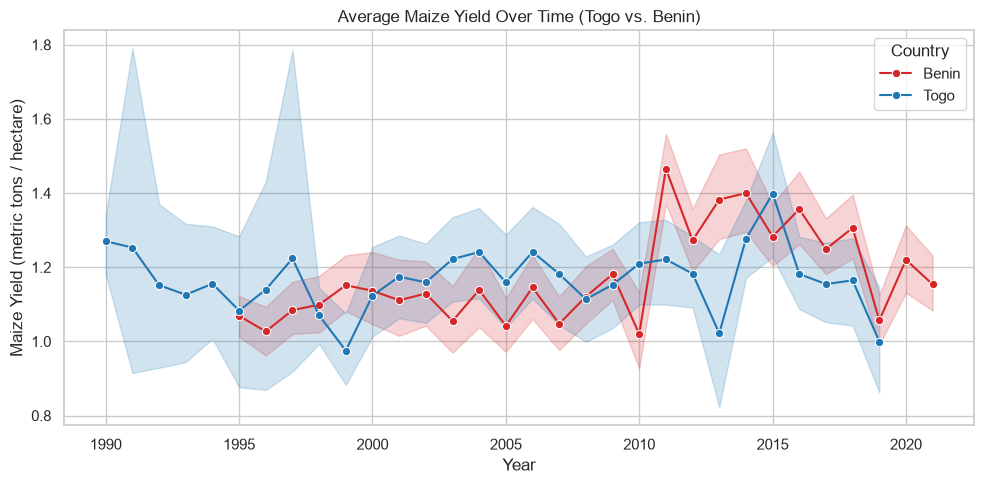

In [79]:
# Set visual style
sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(10, 5))

country_colors = {"Togo": "#1f77b4", "Benin": "#d62728"}  # Blue for Togo, Red for Benin

# Plot of the Mean maize yield over time by country (with confidence interval)
sns.lineplot(
    data=df, x='year', y='value', hue='country', marker='o',
    palette=country_colors, ax=ax
)
ax.set_title('Average Maize Yield Over Time (Togo vs. Benin)', fontsize=12)
ax.set_xlabel('Year')
ax.set_ylabel('Maize Yield (metric tons / hectare)')
ax.legend(title='Country')

plt.tight_layout()
plt.show()


### 3. Importing and working on the MODIS VI data 

In [80]:
# Import MODIS VI data without automatic scaling/masking
nc_path = r"instructions and data\data\modis_vegetation_indices\modis_vi.nc"
ds = xr.open_dataset(nc_path, mask_and_scale=False)

# Inspect metadata to check exact attribute names (e.g., 'scale_factor', '_FillValue')
print("NDVI Attributes:", ds["NDVI"].attrs)

# Drop the singleton 'band' dimension -> (time, y, x)
ds = ds.squeeze("band", drop=True)

# Mask invalid data and apply the scale factor (MODIS convention: value / 10000)
for var in ["NDVI", "EVI"]:
    attrs = ds[var].attrs
    scale = float(attrs.get("scale_factor", 10000.0))
    fill_val = attrs.get("_FillValue", -3000)
    vmin, vmax = (float(v) for v in str(attrs.get("valid_range", "-2000, 10000")).split(","))

    raw = ds[var]
    valid = (raw != fill_val) & (raw >= vmin) & (raw <= vmax)
    scaled = raw.where(valid).astype("float32")
    scaled = scaled / scale if scale > 1 else scaled * scale

    # Keep only descriptive attributes (avoid re-scaling if the data is saved later)
    scaled.attrs = {"long_name": attrs.get("long_name", var), "units": attrs.get("units", var)}
    ds[var] = scaled

# Spatial dimensions in this file are 'x' (longitude) and 'y' (latitude)
ds = ds.rio.set_spatial_dims(x_dim="x", y_dim="y")
ds = ds.rio.write_crs("EPSG:4326")

# Quick check: values should now lie between -0.2 and 1.0
for var in ["NDVI", "EVI"]:
    print(f"{var}: min={float(ds[var].min()):.3f}, max={float(ds[var].max()):.3f}, "
          f"NaN share={float(ds[var].isnull().mean()):.1%}")



NDVI Attributes: {'_FillValue': np.int16(-3000), 'add_offset': np.float64(0.0), 'add_offset_err': np.int64(0), 'calibrated_nt': np.int64(5), 'long_name': 'CMG 0.05 Deg Monthly NDVI', 'scale_factor': np.float64(10000.0), 'scale_factor_err': np.int64(0), 'units': 'NDVI', 'valid_range': '-2000, 10000', 'grid_mapping': 'spatial_ref'}
NDVI: min=-0.198, max=0.978, NaN share=2.3%
EVI: min=-0.149, max=0.853, NaN share=2.3%


In [81]:
# Load Administrative Boundaries (Togo + Benin, admin level 2, merged earlier)

admin2_path = "togo_benin_merged.geojson"
gdf_admin2 = gpd.read_file(admin2_path).to_crs("EPSG:4326")

# Dissolve admin 2 to create admin 1 boundaries (regions / departments)
gdf_admin1 = gdf_admin2.dissolve(by=["country_name", "NAME_1"], as_index=False)

# Extract Zonal Statistics (Mean, Min, Max) per Polygon, Year, Month, and VI
# Each polygon is rasterized ONCE (the grid is identical for every month),
# then statistics are computed for all months at once with NumPy.

transform = ds.rio.transform()
grid_shape = (ds.sizes["y"], ds.sizes["x"])
times = pd.to_datetime(ds.time.values)

# Load both indices in memory once: arrays of shape (time, y, x)
arrays = {var: ds[var].values for var in ["NDVI", "EVI"]}

results = []
for _, row in gdf_admin2.iterrows():
    # Boolean mask of pixels touching the polygon (all_touched=True for small communes)
    inside = geometry_mask([row.geometry], out_shape=grid_shape,
                           transform=transform, invert=True, all_touched=True)

    for var, arr in arrays.items():
        pixels = arr[:, inside]                      # shape (time, n_pixels)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)  # all-NaN months -> NaN
            mean = np.nanmean(pixels, axis=1)
            vmin = np.nanmin(pixels, axis=1)
            vmax = np.nanmax(pixels, axis=1)

        results.append(pd.DataFrame({
            "country":  row["country_name"],
            "admin_1":  row["NAME_1"],
            "admin_2":  row["NAME_2"],
            "GID_2":    row["GID_2"],
            "year":     times.year,
            "month":    times.month,
            "index":    var,
            "mean":     mean,
            "min":      vmin,
            "max":      vmax,
            "n_pixels": inside.sum(),
        }))

df_zonal = pd.concat(results, ignore_index=True)
print(df_zonal.shape)
print(df_zonal.head())



(62304, 11)
  country admin_1 admin_2      GID_2  year  month index      mean     min  \
0    Togo  Centre  Blitta  TGO.1.1_2  2002      7  NDVI  0.749293  0.6564   
1    Togo  Centre  Blitta  TGO.1.1_2  2002      8  NDVI  0.744010  0.6464   
2    Togo  Centre  Blitta  TGO.1.1_2  2002      9  NDVI  0.740795  0.6015   
3    Togo  Centre  Blitta  TGO.1.1_2  2002     10  NDVI  0.725807  0.6453   
4    Togo  Centre  Blitta  TGO.1.1_2  2002     11  NDVI  0.646597  0.5501   

      max  n_pixels  
0  0.8495       132  
1  0.8531       132  
2  0.8315       132  
3  0.8015       132  
4  0.7645       132  


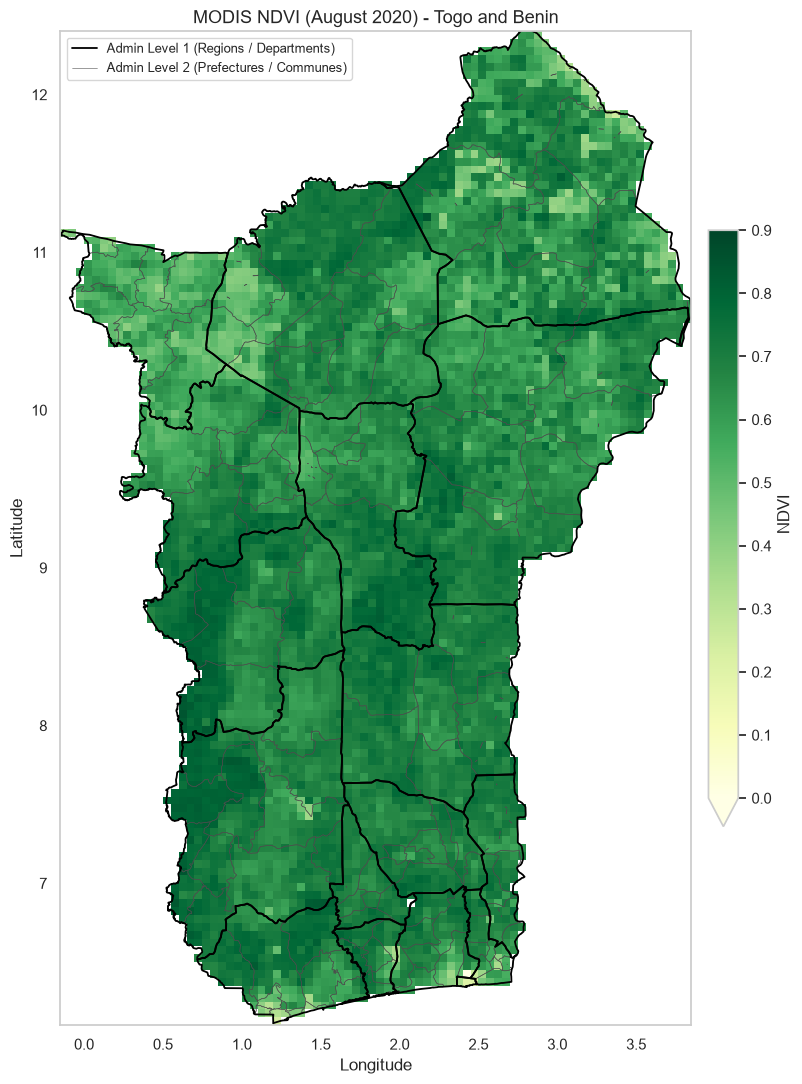

In [82]:
# Plot a single VI layer overlaid with administrative boundaries

# Select a representative growing-season month (e.g., August 2020)
sample_slice = ds["NDVI"].sel(time="2020-08", method="nearest")

# Keep only pixels inside Togo + Benin (removes Ghana, Burkina, Nigeria, Niger)
sample_clip = sample_slice.rio.clip(gdf_admin2.geometry, gdf_admin2.crs, all_touched=False, drop=True)

# Clean Admin 1 lines: close the tiny gaps left by the dissolve (buffer in metres, UTM 31N)
admin1_clean = gdf_admin1.to_crs("EPSG:32631")
admin1_clean["geometry"] = admin1_clean.geometry.buffer(100).buffer(-100)  # 100 m
admin1_clean = admin1_clean.to_crs("EPSG:4326")


fig, ax = plt.subplots(figsize=(9, 11))

sample_clip.plot(
    ax=ax, cmap="YlGn", vmin=0, vmax=0.9,
    cbar_kwargs={"label": "NDVI", "shrink": 0.6, "pad": 0.02},
)
gdf_admin2.boundary.plot(ax=ax, color="#4d4d4d", linewidth=0.4)
admin1_clean.boundary.plot(ax=ax, color="black", linewidth=1.3)

ax.legend(handles=[
    mlines.Line2D([], [], color="black", lw=1.3, label="Admin Level 1 (Regions / Departments)"),
    mlines.Line2D([], [], color="#4d4d4d", lw=0.4, label="Admin Level 2 (Prefectures / Communes)"),
], loc="upper left", fontsize=9, frameon=True)

date_label = pd.to_datetime(sample_slice.time.values).strftime("%B %Y")
ax.set_title(f"MODIS NDVI ({date_label}) - Togo and Benin", fontsize=13)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
ax.grid(False)
plt.tight_layout()
plt.show()


### 4. Reshaping of the extracted data

In [83]:
# Reshape the zonal statistics to wide format (one row per unit-year, 72 VI columns)

# Harmonise the VI side: GADM splits Djougou into 'DjougouRural' and 'DjougouUrbain',
#     whereas FEWS NET reports a single 'Djougou' commune -> aggregate the two units.
#     mean = pixel-weighted mean, min = min of mins, max = max of maxs.
zonal = df_zonal.copy()
zonal.loc[zonal["admin_2"].isin(["DjougouRural", "DjougouUrbain"]), "admin_2"] = "Djougou"
zonal["w_mean"] = zonal["mean"] * zonal["n_pixels"]
keys = ["country", "admin_1", "admin_2", "year", "month", "index"]
zonal = (zonal.groupby(keys, as_index=False)
              .agg(w_mean=("w_mean", "sum"), n_pixels=("n_pixels", "sum"),
                   min=("min", "min"), max=("max", "max")))
zonal["mean"] = zonal["w_mean"] / zonal["n_pixels"]

# Pivot: columns like ndvi_mean_01 ... evi_max_12  (2 indices x 3 stats x 12 months = 72)
vi_wide = zonal.pivot_table(index=["country", "admin_1", "admin_2", "year"],
                            columns=["index", "month"], values=["mean", "min", "max"])
vi_wide.columns = [f"{idx.lower()}_{stat}_{month:02d}" for stat, idx, month in vi_wide.columns]

ordered_cols = [f"{idx}_{stat}_{m:02d}" for idx in ["ndvi", "evi"]
                for stat in ["mean", "min", "max"] for m in range(1, 13)]
vi_wide = vi_wide.reindex(columns=ordered_cols).reset_index()
print(vi_wide.shape)   # 72 VI columns + 4 keys


(2691, 76)


In [84]:
# Clean the maize yield data so that its keys match the GADM / VI keys

yield_df = df[["country", "admin_1", "admin_2", "year", "value"]].rename(columns={"value": "yield_mt_ha"})

# Benin: before 1999 the yield data use the 6 former departments (e.g. Banikoara under
#     'Borgou' instead of 'Alibori'). Commune names are unique in Benin, so the current
#     department is taken from GADM using the commune name.
yield_df["admin_2"] = yield_df["admin_2"].replace({"Djougou Rural": "Djougou"})
benin_lookup = (gdf_admin2.loc[gdf_admin2["country_name"] == "Benin", ["NAME_2", "NAME_1"]]
                .replace({"NAME_2": {"DjougouRural": "Djougou", "DjougouUrbain": "Djougou"}})
                .drop_duplicates().set_index("NAME_2")["NAME_1"])
is_benin = yield_df["country"] == "Benin"
yield_df.loc[is_benin, "admin_1"] = yield_df.loc[is_benin, "admin_2"].map(benin_lookup)

# Togo: 'Mô' is a prefecture of the Centre region only. The 'Mô' records filed under
#     'Maritime' and 'Plateaux' (the latter with 2 different values per year) cannot be
#     attributed to a real prefecture -> they are dropped.
bad_mo = (yield_df["country"] == "Togo") & (yield_df["admin_2"] == "Mô") & (yield_df["admin_1"] != "Centre")
print("Dropped ambiguous Togo 'Mô' records:", bad_mo.sum())
yield_df = yield_df[~bad_mo]

# Sanity checks: no remaining duplicates and every unit exists in GADM
key = ["country", "admin_1", "admin_2", "year"]
assert not yield_df.duplicated(key).any()
gadm_units = set(map(tuple, vi_wide[["country", "admin_1", "admin_2"]].drop_duplicates().values))
unmatched = {u for u in map(tuple, yield_df[key[:3]].drop_duplicates().values) if u not in gadm_units}
print("Yield units not found in GADM:", unmatched)


Dropped ambiguous Togo 'Mô' records: 67
Yield units not found in GADM: set()


In [85]:
# Merge vegetation features with maize yield
#    VI data cover 2002-07 to 2024-06, yields cover 1990-2021 -> inner join keeps 2002-2021.
#    Year Y uses the VI months January-December of Y (main season harvested in Y).
merged = yield_df.merge(vi_wide, on=key, how="inner", validate="one_to_one")

print(merged.shape)
print(merged.groupby("country")["year"].agg(["min", "max", "count"]))
print("Rows with missing VI months (2002 starts in July):",
      merged[ordered_cols].isna().any(axis=1).sum())
merged.head()


(2017, 77)
          min   max  count
country                   
Benin    2002  2021   1522
Togo     2002  2019    495
Rows with missing VI months (2002 starts in July): 107


,country,admin_1,admin_2,year,yield_mt_ha,ndvi_mean_01,ndvi_mean_02,ndvi_mean_03,ndvi_mean_04,ndvi_mean_05,...,evi_max_03,evi_max_04,evi_max_05,evi_max_06,evi_max_07,evi_max_08,evi_max_09,evi_max_10,evi_max_11,evi_max_12
0,Benin,Alibori,Banikoara,2002,1.194343,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.5310,0.5786,0.5645,0.4881,0.3487,0.2313
1,Benin,Alibori,Banikoara,2003,1.468042,0.297755,0.274455,0.257007,0.333267,0.384813,...,0.1833,0.2624,0.3254,0.4606,0.5464,0.5845,0.5732,0.4486,0.4169,0.2230
2,Benin,Alibori,Banikoara,2004,1.454900,0.296825,0.267333,0.261254,0.296910,0.374808,...,0.1731,0.2502,0.3164,0.4303,0.4962,0.6313,0.5400,0.4374,0.3048,0.2211
3,Benin,Alibori,Banikoara,2005,1.501367,0.266389,0.246734,0.238026,0.265047,0.345389,...,0.1764,0.2224,0.3307,0.4199,0.4991,0.5892,0.5715,0.4623,0.3415,0.2248
4,Benin,Alibori,Banikoara,2006,1.375722,0.291790,0.271678,0.264373,0.272380,0.304082,...,0.1877,0.2152,0.2462,0.3732,0.4833,0.5523,0.5511,0.5000,0.3564,0.2395


# Task 2: Modeling and results interpretation

### 1. Comparison of the distribution of yields to a log transformation of yields

In [86]:
# Compare raw yields vs log-transformed yields
from scipy import stats

merged["log_yield"] = np.log(merged["yield_mt_ha"])

# Shape of the distributions
for col in ["yield_mt_ha", "log_yield"]:
    y = merged[col]
    print(f"{col:12s} skew={stats.skew(y):6.2f}  kurtosis={stats.kurtosis(y):6.2f}")


yield_mt_ha  skew=  1.13  kurtosis=  3.31
log_yield    skew= -1.59  kurtosis= 12.13


In [87]:
# Relationship with the vegetation features
vi_cols = [c for c in merged.columns if c.startswith(("ndvi_", "evi_"))]
corr = pd.DataFrame({
    "raw": merged[vi_cols].corrwith(merged["yield_mt_ha"]),
    "log": merged[vi_cols].corrwith(merged["log_yield"]),
})
print(corr.reindex(corr["raw"].abs().sort_values(ascending=False).index).head(10).round(3))
print("Mean |r| raw:", corr["raw"].abs().mean().round(3), " log:", corr["log"].abs().mean().round(3))

                raw    log
evi_mean_12  -0.302 -0.271
ndvi_mean_12 -0.300 -0.274
evi_max_12   -0.291 -0.267
evi_mean_11  -0.289 -0.249
evi_max_11   -0.281 -0.250
ndvi_max_12  -0.269 -0.245
ndvi_min_12  -0.263 -0.226
evi_min_12   -0.258 -0.220
ndvi_mean_01 -0.252 -0.232
ndvi_mean_06 -0.245 -0.229
Mean |r| raw: 0.171  log: 0.158


### 2. Implementation of a cross-validated predictive model

In [88]:
# Control random number generation at all levels
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Features (72 VI columns + admin-2 location) and target (raw yield)
merged["location"] = merged["country"] + " | " + merged["admin_1"] + " | " + merged["admin_2"]
vi_cols = [c for c in merged.columns if c.startswith(("ndvi_", "evi_"))]
X = merged[vi_cols + ["location"]]
y = merged["yield_mt_ha"]

# 80% train/validation - 20% test
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)

# Preprocessing: impute + scale VI features, one-hot encode admin 2 (spatial fixed effects)
preprocess = ColumnTransformer([
    ("vi", Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler())]), vi_cols),
    ("loc", OneHotEncoder(handle_unknown="ignore"), ["location"]),
])
pipe = Pipeline([("prep", preprocess), ("model", Ridge(random_state=SEED))])

# 5-fold cross-validation to tune alpha, metric = R²
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
search = GridSearchCV(pipe, {"model__alpha": np.logspace(-3, 3, 25)}, cv=cv, scoring="r2")
search.fit(X_trainval, y_trainval)

# Validation and test scores
val_r2 = search.best_score_
test_r2 = r2_score(y_test, search.predict(X_test))
print(f"Best alpha: {search.best_params_['model__alpha']:.3g}")
print(f"Validation R² (5-fold CV): {val_r2:.3f}")
print(f"Test R²:                   {test_r2:.3f}")


Best alpha: 1
Validation R² (5-fold CV): 0.385
Test R²:                   0.362


### 3. Summarizing of the data to the first level of administrative division

In [89]:
# Summarise to admin level 1 and rerun the cross-validated model
random.seed(SEED)
np.random.seed(SEED)

# Mean of yield and VI features per country / admin 1 / year
adm1_df = (merged.groupby(["country", "admin_1", "year"], as_index=False)[["yield_mt_ha"] + vi_cols]
                 .mean())
adm1_df["location"] = adm1_df["country"] + " | " + adm1_df["admin_1"]
print(f"Admin-1 dataset: {len(adm1_df)} rows, {adm1_df['location'].nunique()} locations")

X1 = adm1_df[vi_cols + ["location"]]
y1 = adm1_df["yield_mt_ha"]

# 80% train/validation - 20% test
X1_trainval, X1_test, y1_trainval, y1_test = train_test_split(X1, y1, test_size=0.20, random_state=SEED)

# Same pipeline, one-hot encoding admin 1
preprocess1 = ColumnTransformer([
    ("vi", Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler())]), vi_cols),
    ("loc", OneHotEncoder(handle_unknown="ignore"), ["location"]),
])
pipe1 = Pipeline([("prep", preprocess1), ("model", Ridge(random_state=SEED))])

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
search1 = GridSearchCV(pipe1, {"model__alpha": np.logspace(-3, 3, 25)}, cv=cv, scoring="r2")
search1.fit(X1_trainval, y1_trainval)

val_r2_adm1 = search1.best_score_
test_r2_adm1 = r2_score(y1_test, search1.predict(X1_test))
print(f"Best alpha: {search1.best_params_['model__alpha']:.3g}")
print(f"Validation R² (5-fold CV): {val_r2_adm1:.3f}")
print(f"Test R²:                   {test_r2_adm1:.3f}")


Admin-1 dataset: 302 rows, 17 locations
Best alpha: 3.16
Validation R² (5-fold CV): 0.467
Test R²:                   0.476


### 4. Publication-quality scatter plot of the test set predictions (x-axis) vs. reported yields (y-axis).

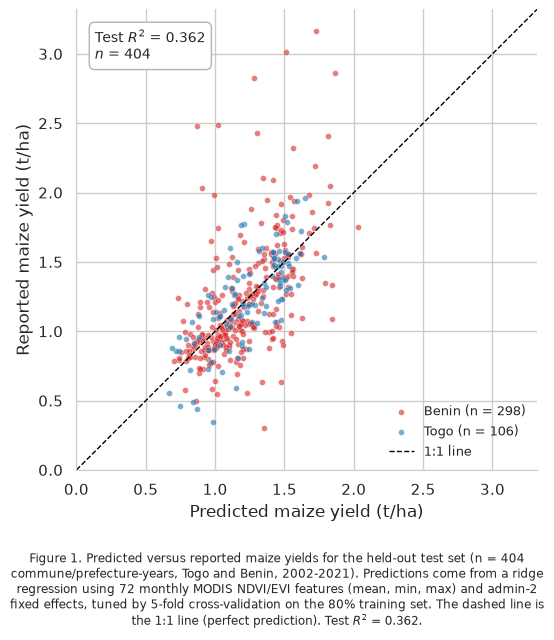

In [ ]:
# Publication-quality figure: test-set predictions vs reported yields
y_pred_test = search.predict(X_test)
test_r2 = r2_score(y_test, y_pred_test)
n_test = len(y_test)

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.linewidth": 0.8,
                     "pdf.fonttype": 42})   # embed fonts as editable text in the PDF

fig, ax = plt.subplots(figsize=(5.5, 5.5))
colors = {"Benin": "#d62728", "Togo": "#1f77b4"}
countries = X_test["location"].str.split(" | ", regex=False).str[0]
for country, color in colors.items():
    m = countries == country
    ax.scatter(y_pred_test[m], y_test[m], s=18, alpha=0.6, color=color,
               edgecolor="white", linewidth=0.3, label=f"{country} (n = {m.sum()})")

# 45-degree reference line
lims = [0, max(y_test.max(), y_pred_test.max()) * 1.05]
ax.plot(lims, lims, color="black", linestyle="--", linewidth=1, label="1:1 line")
ax.set_xlim(lims); ax.set_ylim(lims); ax.set_aspect("equal")

ax.set_xlabel("Predicted maize yield (t/ha)")
ax.set_ylabel("Reported maize yield (t/ha)")
ax.text(0.04, 0.96, f"Test $R^2$ = {test_r2:.3f}\n$n$ = {n_test}", transform=ax.transAxes,
        va="top", fontsize=10, bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="0.7"))
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)

# Figure caption
caption = (f"Figure 1. Predicted versus reported maize yields for the held-out test set "
           f"(n = {n_test} commune/prefecture-years, Togo and Benin, 2002-2021). Predictions come from a "
           f"ridge regression using 72 monthly MODIS NDVI/EVI features (mean, min, max) and admin-2 "
           f"fixed effects, tuned by 5-fold cross-validation on the 80% training set. The dashed line is "
           f"the 1:1 line (perfect prediction). Test $R^2$ = {test_r2:.3f}.")
fig.text(0.5, -0.02, caption, ha="center", va="top", fontsize=8.5, wrap=True)

fig.tight_layout()
fig.savefig("figures folder/2.4.pdf", bbox_inches="tight")
plt.show()
